# Tugas Hands-On 3: Pandas Lanjutan

**Nama:** Sofia Risa Aulia
**NIM:** 23552011299
**Kasus:** Case 8 - Student Performance (EdTech)
**Jenis tugas:** Klasifikasi biner (memprediksi status kelulusan siswa)

Notebook ini mengerjakan lima tahap: (1) memuat data, (2) audit dan pembersihan kualitas data, (3) analisis dan temuan, (4) persiapan data untuk model tanpa data leakage, (5) penyimpanan output.

## 0. Persiapan
Mengimpor library dan menetapkan `random seed = 2026` agar hasil dapat direproduksi.

In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

np.random.seed(2026)
os.makedirs('data', exist_ok=True)
os.makedirs('output', exist_ok=True)

## 1. Memuat data
Dataset diunggah secara manual dari file CSV. Pastikan file `case9_student_performance.csv` diunggah ke Colab sebelum menjalankan sel berikutnya.

In [2]:
from google.colab import files
up = files.upload()   # pilih case9_student_performance.csv

Saving case9_student_performance.csv.csv to case9_student_performance.csv (2).csv


Data dimuat ke `df_mentah` dan tidak diubah lagi. Seluruh pembersihan dilakukan pada salinan bernama `df`.
Hasil awal: 800 baris dan 19 kolom. Hampir semua kolom fitur memiliki missing value. Target `status_kelulusan` tidak memiliki missing value.

In [3]:
import glob
nama_file = sorted(glob.glob('case9_student_performance*.csv'))[-1]
print('Membaca file:', nama_file)
df_mentah = pd.read_csv(nama_file)
df_mentah.to_csv('data/case9_student_performance.csv', index=False)

print(df_mentah.shape)
df_mentah.info()
display(df_mentah.head())
display(df_mentah.describe(include='all').T)

Membaca file: case9_student_performance.csv.csv
(800, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              800 non-null    object 
 1   usia                    778 non-null    float64
 2   jenis_kelamin           776 non-null    object 
 3   jenis_sekolah           779 non-null    object 
 4   pendidikan_orang_tua    773 non-null    object 
 5   pekerjaan_orang_tua     777 non-null    object 
 6   jam_belajar_per_minggu  773 non-null    float64
 7   persentase_kehadiran    774 non-null    float64
 8   ikut_ekskul             766 non-null    object 
 9   akses_internet          757 non-null    object 
 10  les_privat              776 non-null    object 
 11  waktu_tempuh_menit      770 non-null    float64
 12  nilai_matematika        768 non-null    float64
 13  nilai_bahasa_indonesia  769 non-null 

,student_id,usia,jenis_kelamin,jenis_sekolah,pendidikan_orang_tua,pekerjaan_orang_tua,jam_belajar_per_minggu,persentase_kehadiran,ikut_ekskul,akses_internet,les_privat,waktu_tempuh_menit,nilai_matematika,nilai_bahasa_indonesia,nilai_ipa,nilai_ips,nilai_bahasa_inggris,nilai_rata_rata,status_kelulusan
0,STU0001,17.0,Laki-laki,Negeri,S1,PNS,13.0,59.8,Ya,Ya,Ya,138.0,65.0,68.0,44.0,41.0,43.0,52.2,Tidak Lulus
1,STU0002,13.0,Perempuan,Swasta,S2,PNS,11.0,84.8,Ya,Ya,Tidak,65.0,70.0,79.0,54.0,67.0,NaN,64.0,Tidak Lulus
2,STU0003,12.0,Perempuan,Swasta,S1,NaN,4.0,72.0,Tidak,Ya,Tidak,90.0,41.0,53.0,35.0,38.0,NaN,41.6,Tidak Lulus
3,STU0004,12.0,Laki-laki,Swasta,S1,PNS,26.0,73.4,Ya,Ya,NaN,56.0,87.0,73.0,81.0,76.0,52.0,73.8,Lulus
4,STU0005,13.0,Laki-laki,Swasta,SD,PNS,10.0,94.5,Tidak,Ya,Ya,109.0,71.0,75.0,NaN,72.0,74.0,69.8,Lulus


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,800,800,STU0784,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
usia,778.0,NaN,NaN,NaN,14.840617,2.046511,12.0,13.0,15.0,17.0,18.0
jenis_kelamin,776,2,Laki-laki,399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jenis_sekolah,779,2,Negeri,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pendidikan_orang_tua,773,5,SMP,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pekerjaan_orang_tua,777,6,PNS,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jam_belajar_per_minggu,773.0,NaN,NaN,NaN,21.513583,12.15685,1.0,11.0,21.0,32.0,42.0
persentase_kehadiran,774.0,NaN,NaN,NaN,71.814212,15.866712,45.0,57.3,71.65,85.2,99.8
ikut_ekskul,766,2,Tidak,396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
akses_internet,757,2,Ya,535,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df_mentah.dtypes)
print(df_mentah.isnull().sum())
print(df_mentah.nunique())

student_id                 object
usia                      float64
jenis_kelamin              object
jenis_sekolah              object
pendidikan_orang_tua       object
pekerjaan_orang_tua        object
jam_belajar_per_minggu    float64
persentase_kehadiran      float64
ikut_ekskul                object
akses_internet             object
les_privat                 object
waktu_tempuh_menit        float64
nilai_matematika          float64
nilai_bahasa_indonesia    float64
nilai_ipa                 float64
nilai_ips                 float64
nilai_bahasa_inggris      float64
nilai_rata_rata           float64
status_kelulusan           object
dtype: object
student_id                 0
usia                      22
jenis_kelamin             24
jenis_sekolah             21
pendidikan_orang_tua      27
pekerjaan_orang_tua       23
jam_belajar_per_minggu    27
persentase_kehadiran      26
ikut_ekskul               34
akses_internet            43
les_privat                24
waktu_tempuh_menit   

### Konfigurasi kolom
- `TARGET`: `status_kelulusan` (yang diprediksi)
- `KUNCI`: `student_id` (ID unik siswa, 800 nilai unik)
- `KOLOM_NUM`: `nilai_matematika` (kolom numerik utama untuk audit outlier)
- `KOLOM_GRUP`: `jenis_sekolah` (2 kategori: Negeri dan Swasta)

In [5]:
TARGET     = 'status_kelulusan'
KUNCI      = 'student_id'
KOLOM_NUM  = 'nilai_matematika'
KOLOM_GRUP = 'jenis_sekolah'

### Cek target
Target berisi dua kelas: Lulus (493 siswa, 61,6%) dan Tidak Lulus (307 siswa, 38,4%). Proporsinya cukup seimbang, tetapi tetap digunakan `stratify` saat split.

In [6]:
print(df_mentah[TARGET].unique())
print(df_mentah[TARGET].value_counts())

['Tidak Lulus' 'Lulus']
status_kelulusan
Lulus          493
Tidak Lulus    307
Name: count, dtype: int64


### Cek rentang nilai
Semua nilai masih wajar: usia 12-18 tahun, kehadiran 45-99,8%, seluruh nilai 0-100, waktu tempuh 5-150 menit. Nilai minimum 0 pada `nilai_bahasa_inggris` dibiarkan karena masih mungkin terjadi.

In [7]:
display(df_mentah.describe().T)

,count,mean,std,min,25%,50%,75%,max
usia,778.0,14.840617,2.046511,12.0,13.0,15.00,17.00,18.0
jam_belajar_per_minggu,773.0,21.513583,12.156850,1.0,11.0,21.00,32.00,42.0
persentase_kehadiran,774.0,71.814212,15.866712,45.0,57.3,71.65,85.20,99.8
waktu_tempuh_menit,770.0,77.071429,41.519906,5.0,40.0,78.50,113.75,150.0
nilai_matematika,768.0,71.006510,19.902335,18.0,56.0,72.00,87.00,100.0
nilai_bahasa_indonesia,769.0,75.600780,18.991515,31.0,61.0,77.00,94.00,100.0
nilai_ipa,757.0,68.597094,20.438452,13.0,53.0,70.00,85.00,100.0
nilai_ips,769.0,73.109233,20.058730,11.0,59.0,74.00,90.00,100.0
nilai_bahasa_inggris,752.0,67.128989,22.223969,0.0,51.0,70.00,86.00,100.0
nilai_rata_rata,775.0,70.695484,18.463492,25.6,55.9,71.60,86.40,100.0


### Cek konsistensi label kategori
Seluruh kolom kategori sudah konsisten (tidak ada penulisan ganda seperti "Ya" dan "ya"), sehingga tidak perlu standarisasi label.

In [8]:
kolom_kat = df_mentah.select_dtypes(exclude='number').columns.drop(KUNCI)
for c in kolom_kat:
    print(c, '->', df_mentah[c].unique())

jenis_kelamin -> ['Laki-laki' 'Perempuan' nan]
jenis_sekolah -> ['Negeri' 'Swasta' nan]
pendidikan_orang_tua -> ['S1' 'S2' 'SD' 'SMP' 'SMA' nan]
pekerjaan_orang_tua -> ['PNS' nan 'Wiraswasta' 'Petani' 'Tidak Bekerja' 'Karyawan Swasta' 'Buruh']
ikut_ekskul -> ['Ya' 'Tidak' nan]
akses_internet -> ['Ya' 'Tidak' nan]
les_privat -> ['Ya' 'Tidak' nan]
status_kelulusan -> ['Tidak Lulus' 'Lulus']


## 2. Audit dan pembersihan kualitas data
Fungsi `cek_kualitas` menghitung jumlah baris, duplikat, missing value, dan outlier (metode IQR per kelompok sekolah). Urutan pembersihan: **duplikat, missing value, outlier, tipe data**.

In [9]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

print(cek_kualitas(df_mentah, KOLOM_NUM, KOLOM_GRUP, KUNCI))

n_baris       800
n_duplikat      0
n_missing     511
n_outlier       0
dtype: int64


### 2a. Duplikat
Duplikat dicek berdasarkan `student_id`. Alasannya: satu siswa tidak boleh muncul dua kali karena membuat model bias. Hasil: **0 duplikat**, sehingga tidak ada baris yang dibuang.

In [10]:
df = df_mentah.copy()

sebelum = len(df)
df = df.drop_duplicates(subset=KUNCI, keep='first')
print('Duplikat dibuang:', sebelum - len(df))

Duplikat dibuang: 0


### 2b. Missing value dan validasi rentang
- Baris dengan target kosong akan dibuang karena tidak bisa dipakai belajar. Hasil: tidak ada.
- Nilai di luar rentang wajar (nilai di luar 0-100, kehadiran di luar 0-100, usia di luar 5-25) dicek. Hasil: **0 nilai tidak valid**.
- Kolom dengan missing lebih dari 50% akan dibuang. Hasil: tidak ada kolom yang dibuang.

**Keputusan penting:** missing value pada kolom fitur (total 511 sel) **sengaja belum diisi** di tahap ini. Imputasi dilakukan setelah split lewat pipeline, agar imputer hanya di-fit pada data train dan tidak terjadi data leakage.

In [11]:
# a) baris dengan target kosong dibuang
df = df.dropna(subset=[TARGET])

# b) buktikan tidak ada nilai di luar rentang wajar
kolom_nilai = [c for c in df.columns if c.startswith('nilai_')]
print('Nilai di luar 0-100  :', ((df[kolom_nilai] < 0) | (df[kolom_nilai] > 100)).sum().sum())
print('Kehadiran di luar 0-100:', ((df['persentase_kehadiran'] < 0) | (df['persentase_kehadiran'] > 100)).sum())
print('Usia di luar 5-25     :', ((df['usia'] < 5) | (df['usia'] > 25)).sum())

# c) kolom dengan missing > 50% dibuang
kolom_buang = df.columns[df.isnull().mean() > 0.5]
df = df.drop(columns=kolom_buang)
print('Kolom dibuang:', list(kolom_buang))
print('Sisa missing:', df.isnull().sum().sum())

Nilai di luar 0-100  : 0
Kehadiran di luar 0-100: 0
Usia di luar 5-25     : 0
Kolom dibuang: []
Sisa missing: 511


### 2c. Outlier
Outlier dideteksi dengan metode IQR per jenis sekolah, lalu nilai ekstrem di-**clip** (ditahan pada batas) dan tidak dibuang. Alasan: data hanya 800 baris sehingga membuang baris terlalu mahal. Clip menjaga jumlah data.
Hasil pengecekan seluruh kolom numerik: hanya **1 outlier** (pada `nilai_bahasa_inggris`), sehingga dampak clip sangat kecil.

In [12]:
def clip_outlier_grup(d, kolom, grup):
    g = d.groupby(grup, observed=True)[kolom]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return d[kolom].clip(lower=q1 - 1.5*iqr, upper=q3 + 1.5*iqr)

kolom_angka = ['jam_belajar_per_minggu', 'persentase_kehadiran', 'waktu_tempuh_menit'] + kolom_nilai
for c in kolom_angka:
    df[c] = clip_outlier_grup(df, c, KOLOM_GRUP)

### 2d. Tipe data
- Target diubah ke angka: Tidak Lulus = 0, Lulus = 1.
- `student_id` dijadikan teks.
- Kolom kategori dijadikan tipe `category`.

In [13]:
df[TARGET] = df[TARGET].map({'Tidak Lulus': 0, 'Lulus': 1})
df[KUNCI] = df[KUNCI].astype(str)

kolom_kategori = df.select_dtypes(include='object').columns.drop(KUNCI)
df[kolom_kategori] = df[kolom_kategori].astype('category')

print(df[TARGET].value_counts())
df.info()

status_kelulusan
1    493
0    307
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   student_id              800 non-null    object  
 1   usia                    778 non-null    float64 
 2   jenis_kelamin           776 non-null    category
 3   jenis_sekolah           779 non-null    category
 4   pendidikan_orang_tua    773 non-null    category
 5   pekerjaan_orang_tua     777 non-null    category
 6   jam_belajar_per_minggu  773 non-null    float64 
 7   persentase_kehadiran    774 non-null    float64 
 8   ikut_ekskul             766 non-null    category
 9   akses_internet          757 non-null    category
 10  les_privat              776 non-null    category
 11  waktu_tempuh_menit      770 non-null    float64 
 12  nilai_matematika        768 non-null    float64 
 13  nilai_bahasa_indone

### 2e. Laporan kualitas: sebelum vs sesudah

In [14]:
laporan = pd.DataFrame({
    'sebelum': cek_kualitas(df_mentah, KOLOM_NUM, KOLOM_GRUP, KUNCI),
    'sesudah': cek_kualitas(df,        KOLOM_NUM, KOLOM_GRUP, KUNCI),
})
display(laporan)
laporan.to_csv('laporan_kualitas.csv')

,sebelum,sesudah
n_baris,800,800
n_duplikat,0,0
n_missing,511,511
n_outlier,0,0


**Interpretasi:** Data awal sudah cukup bersih: tidak ada duplikat, tidak ada nilai di luar rentang, dan outlier hampir tidak ada (fungsi `cek_kualitas` hanya mengukur `nilai_matematika`, sedangkan pengecekan seluruh kolom di sel berikutnya menemukan 1 outlier di `nilai_bahasa_inggris` yang sudah di-clip). Jumlah missing value tetap 511 sebelum dan sesudah karena imputasi sengaja dilakukan setelah split, bukan pada tahap pembersihan.

Pengecekan outlier untuk seluruh kolom numerik (bukan hanya `nilai_matematika`), menggunakan IQR per jenis sekolah pada data mentah.

In [15]:
for c in kolom_angka:
    g = df_mentah.groupby(KOLOM_GRUP, observed=True)[c]
    q1 = g.transform(lambda s: s.quantile(0.25)); q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    n = ((df_mentah[c] < q1 - 1.5*iqr) | (df_mentah[c] > q3 + 1.5*iqr)).sum()
    print(f'{c:25s} outlier: {n}')

jam_belajar_per_minggu    outlier: 0
persentase_kehadiran      outlier: 0
waktu_tempuh_menit        outlier: 0
nilai_matematika          outlier: 0
nilai_bahasa_indonesia    outlier: 0
nilai_ipa                 outlier: 0
nilai_ips                 outlier: 0
nilai_bahasa_inggris      outlier: 1
nilai_rata_rata           outlier: 0


## 3. Analisis

### 3a. Pengecekan data leakage
`nilai_rata_rata` hampir sama dengan rata-rata kelima nilai mata pelajaran. Rentang nilainya juga tidak tumpang tindih antara dua kelas: siswa Tidak Lulus maksimal 64,8, siswa Lulus minimal 65,0. Artinya kelulusan ditentukan oleh aturan **rata-rata nilai ≥ 65**.

Konsekuensi: seluruh kolom `nilai_*` adalah **bocoran target** dan **tidak dipakai sebagai fitur** pada tahap model. Kolom tersebut tetap disimpan di data bersih dan boleh dipakai untuk analisis deskriptif.

In [16]:
mapel = [c for c in kolom_nilai if c != 'nilai_rata_rata']
selisih = (df['nilai_rata_rata'] - df[mapel].mean(axis=1)).abs()
print('Selisih rata-rata:', selisih.mean().round(3))

display(df.groupby(TARGET)['nilai_rata_rata'].agg(['min', 'max', 'mean']).round(1))

Selisih rata-rata: 0.415


,min,max,mean
status_kelulusan,,,
0,25.6,64.8,50.9
1,65.0,100.0,83.2


### 3b. Tingkat kelulusan per kategori
Perbedaan terbesar: les privat (67,4% vs 57,8%), akses internet (63,6% vs 57,2%), dan pendidikan orang tua S2 (68,0% dibanding sekitar 60% pada jenjang lain). Jenis kelamin, jenis sekolah, dan ikut ekskul hanya berbeda 1 sampai 2 poin sehingga pengaruhnya kecil.

In [17]:
# tingkat kelulusan per kategori
for c in kolom_kategori:
    display(df.groupby(c, observed=True)[TARGET]
              .agg(jumlah='count', tingkat_lulus='mean').round(3))

,jumlah,tingkat_lulus
jenis_kelamin,,
Laki-laki,399,0.622
Perempuan,377,0.607


,jumlah,tingkat_lulus
jenis_sekolah,,
Negeri,394,0.629
Swasta,385,0.605


,jumlah,tingkat_lulus
pendidikan_orang_tua,,
S1,148,0.595
S2,147,0.680
SD,159,0.597
SMA,151,0.596
SMP,168,0.601


,jumlah,tingkat_lulus
pekerjaan_orang_tua,,
Buruh,115,0.574
Karyawan Swasta,116,0.629
PNS,152,0.645
Petani,129,0.589
Tidak Bekerja,140,0.629
Wiraswasta,125,0.600


,jumlah,tingkat_lulus
ikut_ekskul,,
Tidak,396,0.601
Ya,370,0.624


,jumlah,tingkat_lulus
akses_internet,,
Tidak,222,0.572
Ya,535,0.636


,jumlah,tingkat_lulus
les_privat,,
Tidak,509,0.578
Ya,267,0.674


### 3c. Kehadiran dan jam belajar
Kehadiran dan jam belajar dikelompokkan menjadi beberapa tingkat. Tingkat kelulusan naik tajam seiring kehadiran dan jam belajar yang makin tinggi: kelompok kehadiran < 60% lulus 46,4% sedangkan > 90% lulus 77,5%, dan kelompok belajar ≤ 11 jam hanya lulus 3,6% sedangkan > 21 jam lulus lebih dari 95%.

In [18]:
df['kelompok_hadir'] = pd.cut(df['persentase_kehadiran'], [0, 60, 75, 90, 100],
                              labels=['<60', '60-75', '75-90', '>90'])
display(df.groupby('kelompok_hadir', observed=True)[TARGET]
          .agg(jumlah='count', tingkat_lulus='mean').round(3))

df['kelompok_belajar'] = pd.qcut(df['jam_belajar_per_minggu'], 4, duplicates='drop')
display(df.groupby('kelompok_belajar', observed=True)[TARGET]
          .agg(jumlah='count', tingkat_lulus='mean').round(3))

,jumlah,tingkat_lulus
kelompok_hadir,,
<60,235,0.464
60-75,198,0.626
75-90,212,0.670
>90,129,0.775


,jumlah,tingkat_lulus
kelompok_belajar,,
"(0.999, 11.0]",197,0.036
"(11.0, 21.0]",194,0.495
"(21.0, 32.0]",191,0.958
"(32.0, 42.0]",191,1.000


### 3d. Heatmap: jenis sekolah x kehadiran
[Berdasarkan heatmap, tingkat kelulusan meningkat seiring dengan tingginya persentase kehadiran, baik pada sekolah negeri maupun swasta. Hal ini menunjukkan bahwa kehadiran lebih berpengaruh terhadap tingkat kelulusan dibandingkan jenis sekolah.]

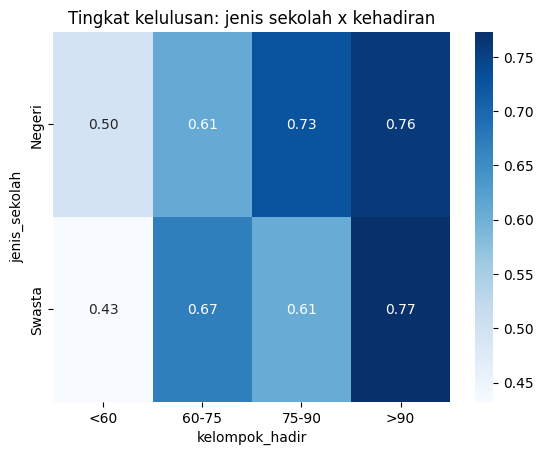

In [19]:
pv = df.pivot_table(index='jenis_sekolah', columns='kelompok_hadir',
                    values=TARGET, aggfunc='mean', observed=True)
sns.heatmap(pv, annot=True, fmt='.2f', cmap='Blues')
plt.title('Tingkat kelulusan: jenis sekolah x kehadiran')
plt.show()

### 3e. Korelasi fitur numerik dengan target
[Berdasarkan grafik, fitur nilai_rata_rata memiliki korelasi paling tinggi dengan status kelulusan, diikuti oleh nilai Bahasa Indonesia, IPS, IPA, Matematika, dan Bahasa Inggris. Namun, fitur-fitur nilai tersebut memiliki korelasi tinggi karena berpotensi mengalami kebocoran target (target leakage), sehingga tidak digunakan dalam pemodelan.]

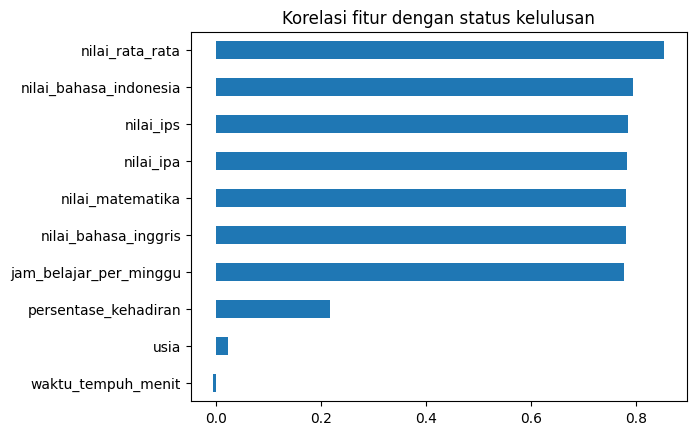

In [20]:
kor = df.select_dtypes('number').corr()[TARGET].drop(TARGET).sort_values()
kor.plot(kind='barh', title='Korelasi fitur dengan status kelulusan')
plt.show()

### 3f. Catatan analisis
- **Time series dilewati:** dataset tidak memiliki kolom tanggal.
- **RFM dilewati:** dataset tidak memiliki data pelanggan dan transaksi, jadi RFM tidak relevan.

### Tiga temuan yang bisa ditindaklanjuti
1. **Jam belajar adalah pembeda paling kuat.** Siswa yang belajar ≤ 11 jam per minggu hanya lulus 3,6%, sedangkan yang belajar > 21 jam lulus 95,8% sampai 100%. Tindakan: prioritaskan pendampingan belajar bagi siswa yang belajar kurang dari 11 jam per minggu.
2. **Kehadiran rendah menurunkan peluang lulus.** Kelompok kehadiran < 60% lulus 46,4%, sedangkan > 90% lulus 77,5% (selisih sekitar 31 poin). Tindakan: pasang peringatan dini bagi siswa yang kehadirannya turun di bawah 60%.
3. **Dukungan belajar di luar sekolah membantu.** Siswa yang ikut les privat lulus 67,4% (vs 57,8%) dan yang punya akses internet lulus 63,6% (vs 57,2%). Tindakan: sediakan subsidi les atau akses internet untuk siswa yang kurang mampu.

*Catatan:* ini adalah asosiasi, bukan bukti sebab-akibat, dan pola jam belajar yang sangat ekstrem menunjukkan dataset ini kemungkinan data simulasi.

## 4. Persiapan data untuk model
Urutan: pisahkan fitur dan target, **split dulu**, baru imputasi, scaling, dan encoding.
- Kolom `student_id`, kolom bantu kelompok, dan seluruh kolom `nilai_*` dibuang dari fitur (alasan: ID tidak punya makna prediktif dan kolom nilai adalah bocoran target).
- Split 80:20 dengan `stratify=y` agar proporsi lulus/tidak lulus sama di train dan test.
- Pipeline numerik: imputasi median lalu StandardScaler. Pipeline kategori: imputasi modus lalu OneHotEncoder.
- `fit` hanya pada data train, data test hanya `transform`, sehingga tidak ada data leakage.

In [21]:
buang = [TARGET, KUNCI, 'kelompok_hadir', 'kelompok_belajar'] + kolom_nilai
X = df.drop(columns=buang)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2026)

num_cols = X_train.select_dtypes('number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[cat_cols] = X_train[cat_cols].astype(object)   # hindari masalah dtype category
X_test[cat_cols]  = X_test[cat_cols].astype(object)

num_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
cat_pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                     ('oh',  OneHotEncoder(handle_unknown='ignore'))])
pre = ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])

X_train_p = pre.fit_transform(X_train)   # fit hanya di train
X_test_p  = pre.transform(X_test)
print(X_train_p.shape, X_test_p.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(640, 25) (160, 25)
0.616 0.619


**Hasil:** data train 640 baris dan data test 160 baris, dengan 25 fitur setelah encoding. Proporsi kelas lulus pada train (0,616) dan test (0,619) hampir sama, menandakan stratify berhasil.

In [22]:
df_final = df.drop(columns=['kelompok_hadir', 'kelompok_belajar'])
df_final.to_csv('output/data_bersih.csv', index=False)

kamus = pd.DataFrame({
    'kolom':     df_final.columns,
    'tipe':      df_final.dtypes.astype(str).values,
    'n_missing': df_final.isnull().sum().values,
    'n_unik':    df_final.nunique().values,
})
kamus.to_csv('output/kamus_data.csv', index=False)
display(kamus)

,kolom,tipe,n_missing,n_unik
0,student_id,object,0,800
1,usia,float64,22,7
2,jenis_kelamin,category,24,2
3,jenis_sekolah,category,21,2
4,pendidikan_orang_tua,category,27,5
5,pekerjaan_orang_tua,category,23,6
6,jam_belajar_per_minggu,float64,27,42
7,persentase_kehadiran,float64,26,415
8,ikut_ekskul,category,34,2
9,akses_internet,category,43,2


## 5. Menyimpan output
`data_bersih.csv` berisi data hasil pembersihan (kolom bantu analisis dibuang), `kamus_data.csv` berisi nama kolom, tipe, jumlah missing, dan jumlah nilai unik. Pada `data_bersih.csv`, target `status_kelulusan` bernilai 1 = Lulus dan 0 = Tidak Lulus. Missing value fitur masih ada di file ini karena ditangani di pipeline.

In [23]:
  buang = [TARGET, KUNCI, 'kelompok_hadir', 'kelompok_belajar'] + kolom_nilai